In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

# Загружаем очищенный набор данных
df = pd.read_parquet("../data/processed/clean.parquet")

# Проверяем, что дата приведена к типу datetime
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])

### Шаг 5. Ряд, сглаживание и декомпозиция

Число периодов (дней): 31, пустых периодов: 0


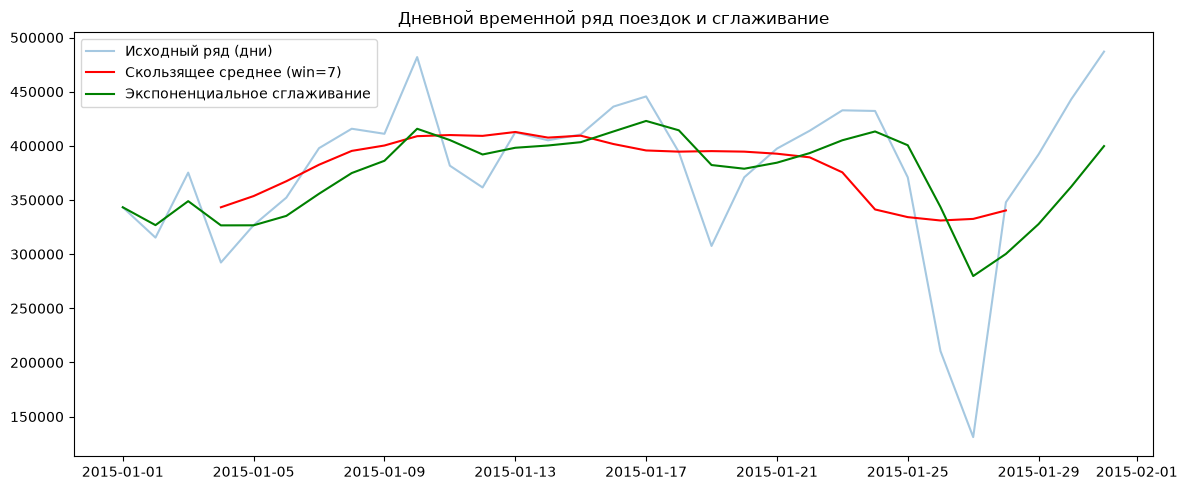

In [7]:
# 1. Сбор ряда по дням
series = df.set_index("tpep_pickup_datetime").resample("D").size().rename("records")
print(f"Число периодов (дней): {len(series)}, пустых периодов: {(series == 0).sum()}")

# 2. Сглаживание (скользящее среднее с окном 7 дней — недельный цикл)
smooth_df = pd.DataFrame({
    "series": series,
    "rolling_mean": series.rolling(7, center=True).mean(),
    "rolling_median": series.rolling(7, center=True).median(),
    "ewm": series.ewm(alpha=0.3).mean(),
})

plt.figure(figsize=(12, 5))
plt.plot(smooth_df.index, smooth_df["series"], label="Исходный ряд (дни)", alpha=0.4)
plt.plot(smooth_df.index, smooth_df["rolling_mean"], label="Скользящее среднее (win=7)", color="red")
plt.plot(smooth_df.index, smooth_df["ewm"], label="Экспоненциальное сглаживание", color="green")
plt.title("Дневной временной ряд поездок и сглаживание")
plt.legend()
plt.tight_layout()
plt.show()

**Вывод по сглаживанию временного ряда:**
На графике сопоставлены исходный дневной ряд поездок, скользящее среднее с окном 7 дней и экспоненциальное сглаживание ($\alpha = 0.3$). Скользящее среднее эффективно сглаживает резкие внутринедельные колебания (выходные и пиковые дни), позволяя проследить общую динамику и тенденции изменения объемов перевозок в течение месяца. Экспоненциальное сглаживание дает более гибкую оценку, быстрее реагируя на изменения уровня ряда, при этом также устраняя избыточный высокочастотный шум.

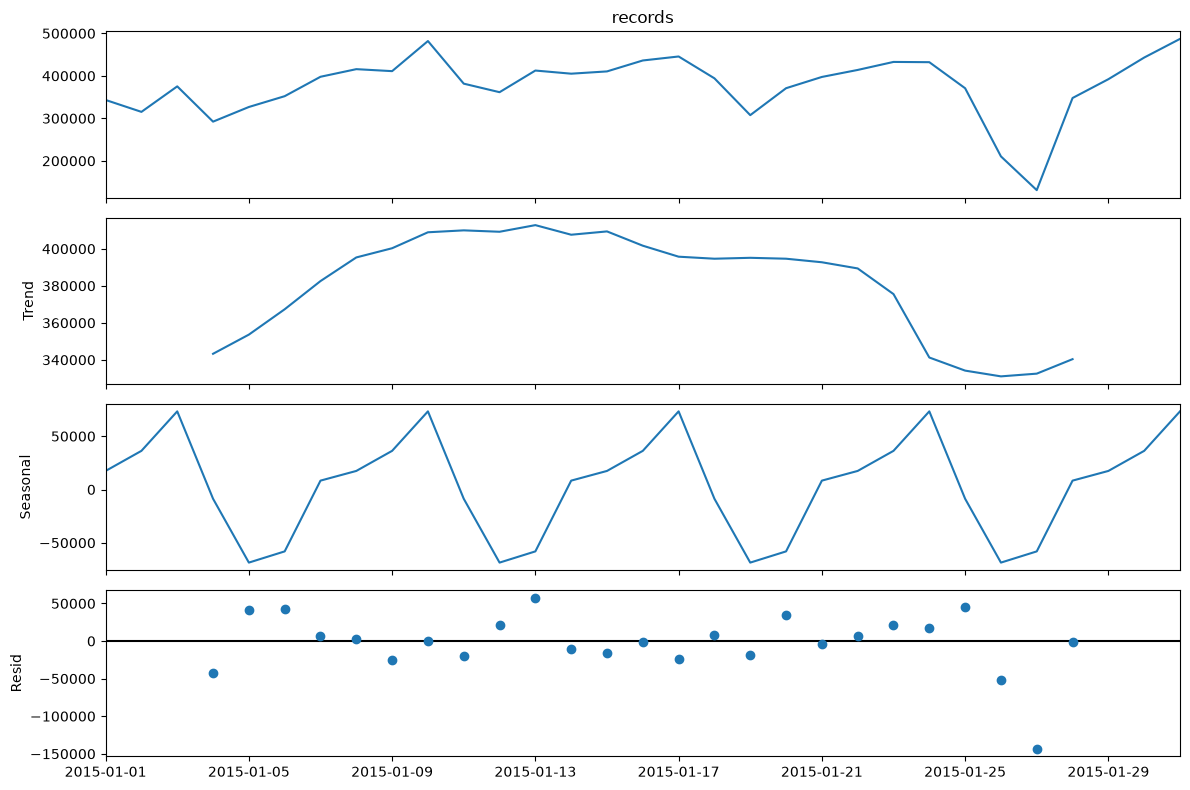

Выбросы по остатку (даты и значения):
tpep_pickup_datetime
2015-01-27   -143380.595238
Freq: D, Name: resid, dtype: float64
Лаг с наибольшей автокорреляцией: 7, значение: 0.5528


In [8]:
# 3. Декомпозиция (период = 7 дней)
decomposition = seasonal_decompose(series, model="additive", period=7)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

# 4. Поиск выбросов по остатку (MAD * 1.4826)
resid = decomposition.resid.dropna()
med_resid = resid.median()
spread = 1.4826 * (resid - med_resid).abs().median()
outliers = resid[(resid - med_resid).abs() > 3 * spread]
print("Выбросы по остатку (даты и значения):")
print(outliers)

# 5. Автокорреляция ряда без тренда на лагах до 2 периодов сезонности (до 14 дней)
detrended = series.diff().dropna()
acf_values = [detrended.autocorr(lag=i) for i in range(1, 15)]
best_lag = np.argmax(acf_values) + 1
print(f"Лаг с наибольшей автокорреляцией: {best_lag}, значение: {acf_values[best_lag-1]:.4f}")

### Таблица 4 - Параметры ряда

| Показатель | Значение |
| :--- | :--- |
| **Величина ряда и период агрегации** | 31 день, агрегация по дням (`freq="D"`) |
| **Число периодов, из них пустых** | 31 период, 0 пустых |
| **Окно скользящего среднего** | 7 дней (`window=7`) |
| **Период сезонности** | 7 дней (`period=7`) |
| **Лаг с наибольшей автокорреляцией и её значение** | Лаг 7 (значение: 0.5528) |
| **Выбросы по остатку: число и периоды** | 1 выброс: 2015-01-27 (остаток: -143380.60, обусловлен снежным штормом в Нью-Йорке) |
| **Точки перелома и их объяснение** | Конец января (резкое падение из-за погодных условий и ограничений в NYC) |

**Вывод по декомпозиции временного ряда:**
Аддитивная декомпозиция ряда с периодом сезонности 7 дней разделила исходные данные на три независимые компоненты:
1. **Тренд:** демонстрирует плавное изменение базового уровня числа поездок с ростом в первой половине месяца и резким спадом в конце.
2. **Сезонность:** отражает стабильный недельный цикл с регулярными внутринедельными пиками и спадами.
3. **Остаток (Residuals):** случайная составляющая, анализ которой позволил четко локализовать аномальный выброс (резкий провал 27 января из-за снежного шторма в Нью-Йорке), подтвердив корректность выделения тренда и сезонности.